In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

In [3]:
import jax
jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
from flax import linen as nn
import optax
import copy

from typing import Callable

from functools import partial

import tensorflow as tf
import tensorrt

from pyDOE import lhs
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import odeint

import numpy as np

from jax.scipy.optimize import minimize
from scipy.optimize import fsolve

import warnings
import math

from collections import deque

In [4]:
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

Num GPUs Available:  1


In [5]:
print(jax.default_backend())

gpu


In [6]:
def flatten_pytree(params):
  values, tree_info = jax.tree_util.tree_flatten(params)

  no_leaves = len(values)
  shapes = []
  flattened = []

  for i in range(no_leaves):
    flattened.append(values[i].flatten())
    shapes.append(values[i].shape)

  return tree_info, shapes, jnp.concatenate(flattened)


def reconstruct_pytree(tree_info, shapes, flattened):

  values = []
  k = 0
  for i in range(len(shapes)):
    values.append(np.reshape(flattened[k:k+np.prod(shapes[i])], shapes[i]))
    k += np.prod(shapes[i])

  py_tree = jax.tree_util.tree_unflatten(tree_info, values)
  return py_tree

In [7]:
t0, tfinal = 0.0, 1.0

In [8]:
def TodaLatt(w, t):
    
    p1, p2, q1, q2 = w

    p1_t = -jnp.exp(q1 - q2) + jnp.exp(q2 - q1)
    q1_t = p1

    p2_t = jnp.exp(q1 - q2) - jnp.exp(q2 - q1)
    q2_t = p2

    dwdt = [p1_t, p2_t, q1_t, q2_t]

    return dwdt

In [9]:
@jax.jit
def calc_H(p1, p2, q1, q2) :

    H = (p1**2)/2 + (p2**2)/2 + jnp.exp(q1 - q2) + jnp.exp(q2 - q1)

    return H

In [10]:
Hmax = 1.0 + np.exp(2) + np.exp(-2)
Hmin = 2.0

print(Hmin, Hmax)

2.0 8.524391382167263


In [11]:
@jax.jit
def calc_ab(p1, p2, q1, q2) :

    a1 = -0.5*p1
    a2 = -0.5*p2

    b1 = 0.5*jnp.exp(0.5*(q1-q2))
    b2 = 0.5*jnp.exp(0.5*(q2-q1))

    return a1, a2, b1, b2

In [12]:
@jax.jit
def calc_evals(a1, a2, b1, b2) :
    
    eigen1 = ((a1 + a2) - jnp.sqrt((a1 - a2)**2 + 4*b1**2))/2
    eigen2 = ((a1 + a2) + jnp.sqrt((a1 - a2)**2 + 4*b1**2))/2

    evals = jnp.array([eigen1, eigen2])

    return evals

In [13]:
calc_evals(1.0, 2.0, 3.0, 4.0)

Array([-1.54138127,  4.54138127], dtype=float64)

In [14]:
@jax.jit
def calc_evals_pq(p1, p2, q1, q2) :

    a1, a2, b1, b2 = calc_ab(p1, p2, q1, q2)
    
    a1 = jnp.reshape(a1, (-1,))
    a2 = jnp.reshape(a2, (-1,))
    b1 = jnp.reshape(b1, (-1,))
    b2 = jnp.reshape(b2, (-1,))
    
    evals = jax.vmap(calc_evals, (0, 0, 0, 0), 0)(a1, a2, b1, b2)
    evals = jnp.reshape(evals, (-1,))
    
    return evals 

In [15]:
def define_collocation_points(t_bdry, N=100):

    ode_points = t_bdry[0] + (t_bdry[1] - t_bdry[0])*lhs(1, N)

    p1s = np.random.uniform(-1.0, 1.0, size=(N, 1))
    p2s = np.random.uniform(-1.0, 1.0, size=(N, 1))
    q1s = np.random.uniform(-1.0, 1.0, size=(N, 1))
    q2s = np.random.uniform(-1.0, 1.0, size=(N, 1))
    Hs = calc_H(p1s, p2s, q1s, q2s)

    evals = jax.vmap(calc_evals_pq, (0), 0)(p1s, p2s, q1s, q2s)
    Hs_test = 2*(evals[:, :1]**2 + evals[:, 1:]**2)

    ode_points = np.column_stack((ode_points, Hs, evals))
    zsensors = np.column_stack((p1s, p2s, q1s, q2s))
    
    return (ode_points, zsensors)

In [16]:
(de_points, zsensors) = define_collocation_points([t0, tfinal], 100000)
print(de_points.shape, zsensors.shape)

(100000, 4) (100000, 4)


In [17]:
Hmax_act = np.max(de_points[:, 1])
Hmin_act = np.min(de_points[:, 1])

print(Hmax, Hmax_act)
print(Hmin, Hmin_act)

8.524391382167263 8.145188812164662
2.0 2.0006581711254223


In [18]:
class Normalize(nn.Module):
  xmin: float
  xmax: float

  @nn.compact
  def __call__(self, x):
    return 2.0*(x-self.xmin)/(self.xmax - self.xmin) - 1.0

In [19]:
class HardConstraint(nn.Module):
  t0: float
  tfinal: float
  u0: float

  @nn.compact
  def __call__(self, inputs):
    t, nn = inputs
    return self.u0 + (t-self.t0)/(self.tfinal-self.t0)*nn

In [20]:
class CombineBranches(nn.Module):
  @nn.compact
  def __call__(self, inp1, inp2):
    mult = jnp.sum(inp1*inp2, axis=1)
    out = jnp.reshape(mult, (-1,1))
    return out

In [21]:
class MLP(nn.Module):

  layers: int
  units: int

  @nn.compact
  def __call__(self, inp):
    b = inp
    for i in range(self.layers-1):
      b = nn.Dense(self.units)(b)
      b = nn.tanh(b)
    out = nn.Dense(4*self.units)(b)
    return out

In [22]:
class DeepONet(nn.Module):

  t0: float
  tfinal: float
  Hmin: float
  Hmax: float
  layers: int 
  units: int

  @nn.compact
  def __call__(self, tHE, u):

    if u.ndim == 1:
      u = jnp.reshape(u, (1,-1))

    if tHE.ndim == 1:
      tHE = jnp.reshape(tHE, (1,-1)) 

    t_0 = tHE[:, :1]
    H_0 = tHE[:, 1:2]
    eval1_0 = tHE[:, 2:3]
    eval2_0 = tHE[:, 3:]
      
    t_0 = jnp.reshape(t_0, (-1,1))
    t_0_norm = Normalize(self.t0, self.tfinal)(t_0)

    H_0_norm = Normalize(self.Hmin, self.Hmax)(H_0)
   
    p1_0 = u[:, :1]
    p2_0 = u[:, 1:2]
    q1_0 = u[:, 2:3]
    q2_0 = u[:, 3:]

    u = jnp.column_stack((p1_0, p2_0, q1_0, q2_0))

    # b = t_0_norm
    b = jnp.column_stack((t_0_norm, H_0_norm))

    trunk_net = MLP(self.layers, self.units)(b)
    branch_net = MLP(self.layers, self.units)(u)

    trunk_p1 = trunk_net[:, :self.units]
    trunk_p2 = trunk_net[:, self.units:2*self.units]
    trunk_q1 = trunk_net[:, 2*self.units:3*self.units]
    trunk_q2 = trunk_net[:, 3*self.units:]
   
    branch_p1 = branch_net[:, :self.units]
    branch_p2 = branch_net[:, self.units:2*self.units]
    branch_q1 = branch_net[:, 2*self.units:3*self.units]
    branch_q2 = branch_net[:, 3*self.units:]
  
    p1 = CombineBranches()(trunk_p1, branch_p1)
    p2 = CombineBranches()(trunk_p2, branch_p2)
    q1 = CombineBranches()(trunk_q1, branch_q1)
    q2 = CombineBranches()(trunk_q2, branch_q2)
      
    p1 = HardConstraint(self.t0, self.tfinal, p1_0)([t_0, p1])
    p2 = HardConstraint(self.t0, self.tfinal, p2_0)([t_0, p2])
    q1 = HardConstraint(self.t0, self.tfinal, q1_0)([t_0, q1])
    q2 = HardConstraint(self.t0, self.tfinal, q2_0)([t_0, q2])
      
    p1 = jnp.reshape(p1, (-1,))
    p2 = jnp.reshape(p2, (-1,))
    q1 = jnp.reshape(q1, (-1,))
    q2 = jnp.reshape(q2, (-1,))

    return p1, p2, q1, q2

In [23]:
@partial(jax.jit, static_argnums=(2,))
def var_model(t, z, component, params):
  return deeponet.apply(params, t, z)[component][0]

@partial(jax.jit, static_argnums=(2,))
def var(t, z, component, params):
  return jax.vmap(var_model, [0, 0, None, None])(t, z, component, params)

@partial(jax.jit, static_argnums=(2,))
def var_t(t, z, component, params):
  return jax.vmap(jax.grad(var_model, 0), [0, 0, None, None])(t, z, component, params)

@jax.jit
def loss(params, tHE, z):
    
    p1_t_loss_w = 1.0
    p2_t_loss_w = 1.0
    q1_t_loss_w = 1.0
    q2_t_loss_w = 1.0   
    
    diff_loss_w = 1.0
    H_loss_w = 1.0

    t_0 = tHE[:, :1]
    H_0 = tHE[:, 1:2]
    eval1_0 = tHE[:, 2:3]
    eval2_0 = tHE[:, 3:]
    
    p1_0 = z[:, :1]
    p2_0 = z[:, 1:2]
    q1_0 = z[:, 2:3]
    q2_0 = z[:, 3:]
    
    p1 = var(tHE, z, 0, params)
    p2 = var(tHE, z, 1, params)
    q1 = var(tHE, z, 2, params)
    q2 = var(tHE, z, 3, params)
    
    H = calc_H(p1, p2, q1, q2)
    H = jnp.reshape(H, (-1, 1))
    
    dp1_tHE = var_t(tHE, z, 0, params)
    dp2_tHE = var_t(tHE, z, 1, params)
    dq1_tHE = var_t(tHE, z, 2, params)
    dq2_tHE = var_t(tHE, z, 3, params)
        
    p1_t = dp1_tHE[:, 0]
    p2_t = dp2_tHE[:, 0]  
    q1_t = dq1_tHE[:, 0]
    q2_t = dq2_tHE[:, 0]
    
    H_loss = H - H_0
    H_loss = jnp.square(H_loss)
    H_loss = jnp.mean(H_loss)

    p1_t_loss = p1_t - (-jnp.exp(q1 - q2) + jnp.exp(q2 - q1))
    p1_t_loss = jnp.square(p1_t_loss)
    p1_t_loss = jnp.mean(p1_t_loss)

    q1_t_loss = q1_t - p1
    q1_t_loss = jnp.square(q1_t_loss)
    q1_t_loss = jnp.mean(q1_t_loss)
    
    p2_t_loss = p2_t - (jnp.exp(q1 - q2) - jnp.exp(q2 - q1))
    p2_t_loss = jnp.square(p2_t_loss)
    p2_t_loss = jnp.mean(p2_t_loss)
    
    q2_t_loss = q2_t - p2
    q2_t_loss = jnp.square(q2_t_loss)
    q2_t_loss = jnp.mean(q2_t_loss)
        
    diff_loss = p1_t_loss + p2_t_loss + q1_t_loss + q2_t_loss
    
    total_loss = diff_loss + H_loss

    return total_loss

@jax.jit
def train_step(params, pdes, z):
    t = pdes[:, :]
    
    return jax.value_and_grad(loss, has_aux = False)(params, t, z)

@partial(jax.jit, static_argnums=(3,))
def optimize(grads, opt_state, params, optimizer_update):
    updates, opt_state = optimizer_update(grads, opt_state, params)
    params = optax.apply_updates(params, updates)
    return params, opt_state

In [24]:
def train_network(params, des, sensors, epochs=100):

    N = de_points.shape[0]
    
    nr_batches = 10
    batch_size = len(des)//nr_batches
    
    print("batch size:", batch_size)
    
    lr = 1e-3
    optimizer = optax.adam(lr)
    opt_state = optimizer.init(params)
    
    ds_z = tf.data.Dataset.from_tensor_slices(sensors)
    ds_de = tf.data.Dataset.from_tensor_slices(des)
    
    ds = tf.data.Dataset.zip((ds_de, ds_z))
    ds = ds.shuffle(N).batch(batch_size)
    
    epoch_loss = np.zeros(epochs)

    for i in range(epochs):

        for (des_batch, z_batch) in ds:

            loss, grads = train_step(params, des_batch.numpy(), z_batch.numpy())
            params, opt_state = optimize(grads, opt_state, params, optimizer.update)

            epoch_loss[i] += loss

        epoch_loss[i] /= batch_size

        if i % 100  == 0:
            print(f'Loss in epoch {i}: {epoch_loss[i]}')

    return params, epoch_loss

In [25]:
deeponet = DeepONet(t0, tfinal, Hmin, Hmax, layers=4, units=40)

t_init = jnp.full((10, 4), 1.0)
u_init = jnp.full((10, 4), 1.0)

params = deeponet.init(jax.random.PRNGKey(0), t_init, u_init)

In [26]:
param_count = sum(x.size for x in jax.tree.leaves(params))
print(param_count)

20000


In [27]:
epochs = 1000
params, loss = train_network(params, de_points, zsensors, epochs)


batch size: 10000


I0000 00:00:1794425816.241444     473 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 673 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Loss in epoch 0: 0.009112507098902378
Loss in epoch 100: 1.8977641721062358e-05
Loss in epoch 200: 7.217236965763585e-06
Loss in epoch 300: 4.454954386837133e-06
Loss in epoch 400: 3.3794979467903054e-06
Loss in epoch 500: 2.2074271687401964e-06
Loss in epoch 600: 2.3984193958355624e-06
Loss in epoch 700: 3.3000207804401625e-06
Loss in epoch 800: 1.0287562306902948e-06
Loss in epoch 900: 1.834955047555557e-06


In [28]:
params_5000ep = copy.deepcopy(params)

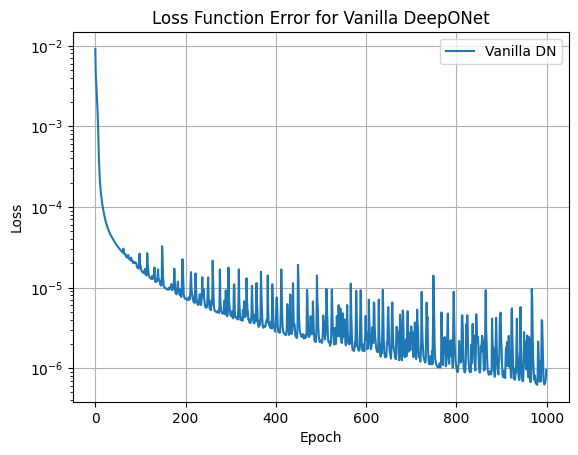

In [29]:
start = 0
stop = 5000

plt.semilogy(loss[start:stop])
plt.legend(['Vanilla DN'])
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.title("Loss Function Error for Vanilla DeepONet")
plt.grid()
#plt.savefig('Toda3_vanilla_loss_5000ep.png')

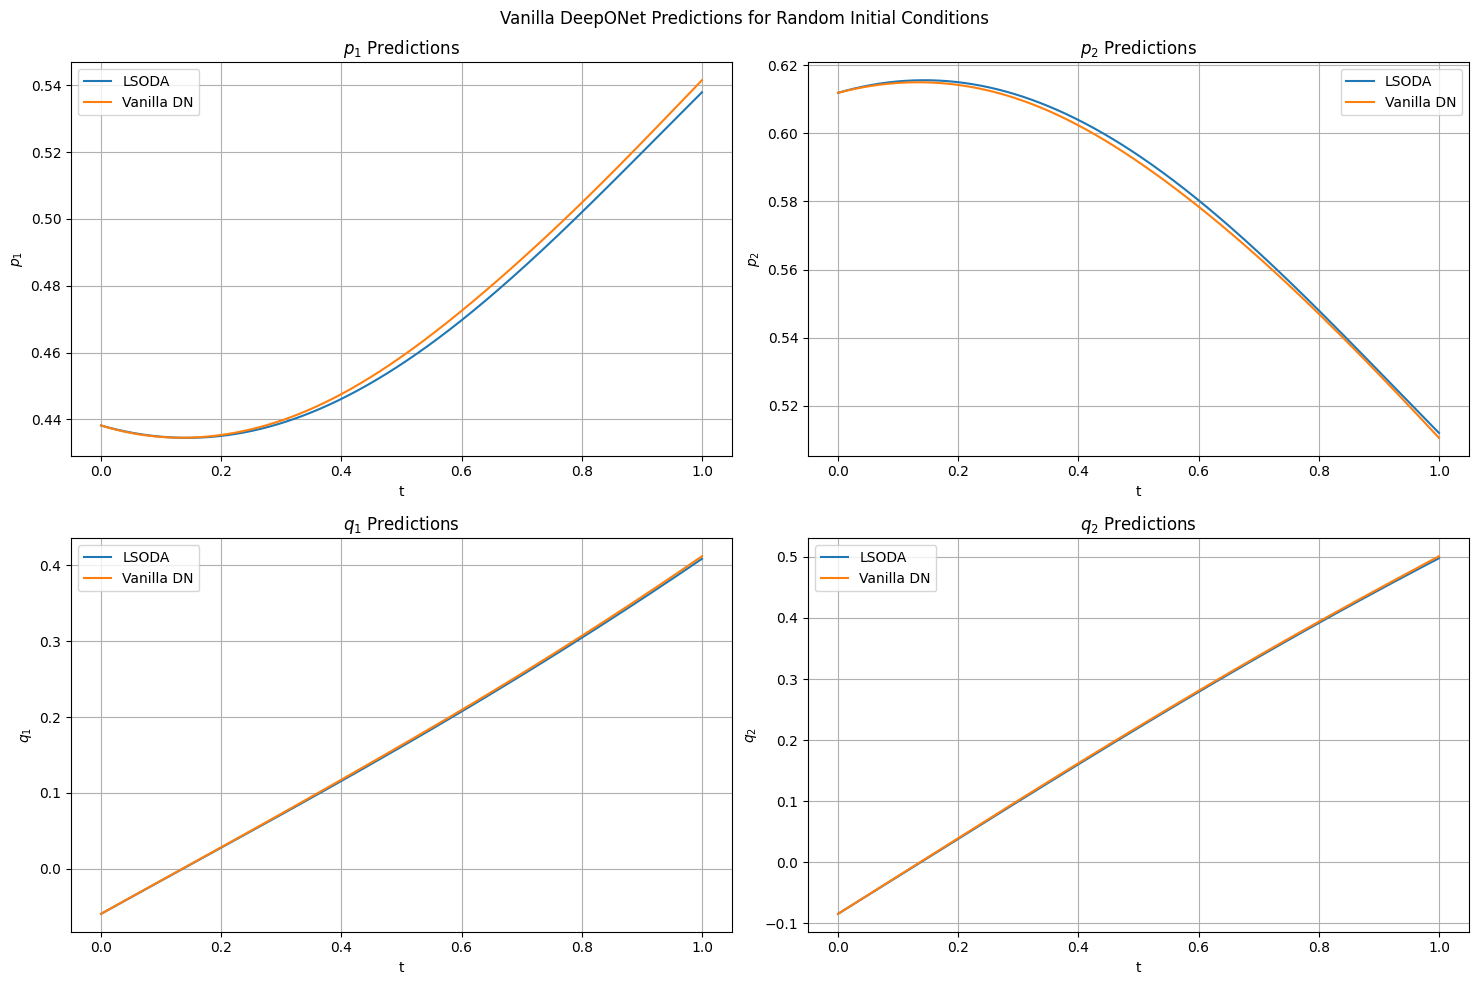

In [34]:
n = 500
t = np.linspace(t0, tfinal, n)

p1_init = np.random.uniform(-1.0, 1.0, size=(1,))
p2_init = np.random.uniform(-1.0, 1.0, size=(1,))
q1_init = np.random.uniform(-1.0, 1.0, size=(1,))
q2_init = np.random.uniform(-1.0, 1.0, size=(1,))
H_init = calc_H(p1_init, p2_init, q1_init, q2_init)
evals_init = calc_evals_pq(p1_init, p2_init, q1_init, q2_init)
e1_init, e2_init = evals_init[0], evals_init[1]


data_model = np.column_stack([p1_init, p2_init, q1_init, q2_init])
data_model = np.reshape(data_model, (-1,))
data_model = np.repeat(np.expand_dims(data_model, axis=0), n, axis=0)

H_model = np.repeat(np.expand_dims(H_init, axis=0), n, axis=0)

E_model = np.column_stack([e1_init, e2_init])
E_model = np.reshape(E_model, (-1,))
E_model = np.repeat(np.expand_dims(E_model, axis=0), n, axis=0)

H_model = np.repeat(np.expand_dims(H_init, axis=0), n, axis=0)
        
tHE_model = np.column_stack([t, H_model, E_model])

p1 = jax.vmap(var_model, [0, 0, None, None])(tHE_model, data_model, 0, params)
p2 = jax.vmap(var_model, [0, 0, None, None])(tHE_model, data_model, 1, params)
q1 = jax.vmap(var_model, [0, 0, None, None])(tHE_model, data_model, 2, params)
q2 = jax.vmap(var_model, [0, 0, None, None])(tHE_model, data_model, 3, params)


data_rk = np.column_stack([p1_init, p2_init, q1_init, q2_init])
data_rk = np.reshape(data_rk, (-1,))
t_rk = t
    
sol_rk = odeint(TodaLatt, data_rk, t_rk, rtol = 1e-13, atol = 1e-13)
p1_rk, p2_rk, q1_rk, q2_rk = sol_rk[:, 0], sol_rk[:, 1], sol_rk[:, 2], sol_rk[:, 3]
H_rk = calc_H(p1_rk, p2_rk, q1_rk, q2_rk)


fig = plt.figure(figsize=(15, 10))
fig.suptitle("Vanilla DeepONet Predictions for Random Initial Conditions")

plt.subplot(2, 2, 1)
plt.tight_layout()
plt.plot(t, p1_rk)
plt.plot(t, p1)
plt.grid()
plt.xlabel('t')
plt.ylabel(r'$p_1$')
plt.title(r'$p_1$' + ' Predictions')
plt.legend(['LSODA', 'Vanilla DN'])


plt.subplot(2, 2, 2)
plt.tight_layout()
plt.plot(t, p2_rk)
plt.plot(t, p2)
plt.grid()
plt.xlabel('t')
plt.ylabel(r'$p_2$')
plt.title(r'$p_2$' + ' Predictions')
plt.legend(['LSODA', 'Vanilla DN'])


plt.subplot(2, 2, 3)
plt.tight_layout()
plt.plot(t, q1_rk)
plt.plot(t, q1)
plt.grid()
plt.xlabel('t')
plt.ylabel(r'$q_1$')
plt.title(r'$q_1$' + ' Predictions')
plt.legend(['LSODA', 'Vanilla DN'])

plt.subplot(2, 2, 4)
plt.tight_layout()
plt.plot(t, q2_rk)
plt.plot(t, q2)
plt.grid()
plt.xlabel('t')
plt.ylabel(r'$q_2$')
plt.title(r'$q_2$' + ' Predictions')
plt.legend(['LSODA', 'Vanilla DN'])


#fig.savefig("Toda3_vanilla_preds_5000ep.png")

In [35]:
@jax.jit
def f_func_newton_eig(args, e_0) :

    args = jnp.reshape(args, (-1,))
    e_0 = jnp.reshape(e_0, (-1,))

    p1, p2, q1, q2 = args[0], args[1], args[2], args[3]
    e1_0, e2_0 = e_0[0], e_0[1]
    
    evals = calc_evals_pq(p1, p2, q1, q2)

    e1, e2 = evals[0], evals[1]

    f1 = e1 - e1_0
    f2 = e2 - e2_0

    f = jnp.array([[f1], [f2]])
    f = jnp.reshape(f, (2, 1))

    return f
    
#@jax.jit
def get_derivs_newton_eig(args, e_0, e, min) :

    a1, a2, b1, b2 = args[0], args[1], args[2], args[3]

    sqrt_d = jnp.sqrt((a1 - a2)**2 + 4*b1**2)

    if min == True :
        
        de_a1 = 1/2 - (a1 - a2)/(2*sqrt_d)
        de_a2 = 1/2 + (a1 - a2)/(2*sqrt_d)
        de_b1 = -2*b1/sqrt_d
        de_b2 = 0.0

    else :

        de_a1 = 1/2 + (a1 - a2)/(2*sqrt_d)
        de_a2 = 1/2 - (a1 - a2)/(2*sqrt_d)
        de_b1 = 2*b1/sqrt_d
        de_b2 = 0.0        

    df_a1 = de_a1
    df_a2 = de_a2
    df_b1 = de_b1
    df_b2 = de_b2

    df_x = (df_a1, df_a2, df_b1, df_b2)

    return df_x


@jax.jit
def gradf_func_newton_eig(args, e_0) :

    e_0 = jnp.reshape(e_0, (-1,))

    p1, p2, q1, q2 = args[0], args[1], args[2], args[3]
    e1_0, e2_0 = e_0[0], e_0[1]

    a1, a2, b1, b2 = calc_ab(p1, p2, q1, q2)
    args_new = (a1, a2, b1, b2)
    
    evals = calc_evals_pq(p1, p2, q1, q2)
    
    e1, e2 = evals[0], evals[1]
 
    df1_a1, df1_a2, df1_b1, df1_b2 = get_derivs_newton_eig(args_new, e1_0, e1, True)
    df2_a1, df2_a2, df2_b1, df2_b2 = get_derivs_newton_eig(args_new, e2_0, e2, False)

    df1_p1, df2_p1 = df1_a1*-0.5, df2_a1*-0.5
    df1_p2, df2_p2 = df1_a2*-0.5, df2_a2*-0.5

    df1_q1 = df1_b1*0.5*b1 + df1_b2*-0.5*b2
    df2_q1 = df2_b1*0.5*b1 + df2_b2*-0.5*b2

    df1_q2 = df1_b1*-0.5*b1 + df1_b2*0.5*b2
    df2_q2 = df2_b1*-0.5*b1 + df2_b2*0.5*b2


    gradf = jnp.array([[df1_p1, df1_p2, df1_q1, df1_q2],
                       [df2_p1, df2_p2, df2_q1, df2_q2]])
    

    gradf = jnp.reshape(gradf, (2, 4))
                    
    return gradf
    
@jax.jit

def newtons_eig_root(x, e_0) :

    iter_num = 0

    e_0 = jnp.reshape(e_0, (-1, 1))

    while iter_num < 5 :

        x = jnp.reshape(x, (-1, 1))
        
        F = f_func_newton_eig(x, e_0)
        J = gradf_func_newton_eig(x, e_0)
        J_inv = jnp.linalg.pinv(J)

        # print(x.shape, F.shape, J.shape, J_inv.shape)

        x = x - J_inv@F

        iter_num = iter_num + 1

    return x

@jax.jit
def find_min_newton_eig(x, e_0) :

    return jnp.squeeze(jax.vmap(newtons_eig_root, (0, 0))(x, e_0))

In [37]:
x_test = jnp.array([[1.0, 2.0, 3.0, 4.0], [1.0, 2.0, 3.0, 4.0]])
e_test = jnp.array([[1.0, 2.0], [1.0, 2.0]])

print(calc_H(1.0, 2.0, 3.0, 4.0))

sol_newton_eig = find_min_newton_eig(x_test, e_test)

p1N, p2N, q1N, q2N = sol_newton_eig[0, 0], sol_newton_eig[0, 1], sol_newton_eig[0, 2], sol_newton_eig[0, 3]

print(p1N, p2N, q1N, q2N, calc_H(p1N, p2N, q1N, q2N))

5.586161269630487
-3.707444744136047 -2.2925552558639524 3.152948115021419 3.847051884978581 12.001914094149557


In [38]:
class EClosestPoint(nn.Module):

    e_0: float
    
    @nn.compact
    def __call__(self, inputs):
    
        x_min = find_min_newton_eig(inputs, self.e_0)
    
        return x_min

In [39]:
class ECDeepONet(nn.Module):

  t0: float
  tfinal: float
  Hmin: float
  Hmax: float
  layers: int 
  units: int

  @nn.compact
  def __call__(self, tHE, u):

    if u.ndim == 1:
      u = jnp.reshape(u, (1,-1))

    if tHE.ndim == 1:
      tHE = jnp.reshape(tHE, (1,-1)) 

    t_0 = tHE[:, :1]
    H_0 = tHE[:, 1:2]
    eval1_0 = tHE[:, 2:3]
    eval2_0 = tHE[:, 3:]
      
    t_0 = jnp.reshape(t_0, (-1,1))
    t_0_norm = Normalize(self.t0, self.tfinal)(t_0)

    H_0_norm = Normalize(self.Hmin, self.Hmax)(H_0)
   
    p1_0 = u[:, :1]
    p2_0 = u[:, 1:2]
    q1_0 = u[:, 2:3]
    q2_0 = u[:, 3:]

    u = jnp.column_stack((p1_0, p2_0, q1_0, q2_0))

    # b = t_0_norm
    b = jnp.column_stack((t_0_norm, H_0_norm))

    trunk_net = MLP(self.layers, self.units)(b)
    branch_net = MLP(self.layers, self.units)(u)

    trunk_p1 = trunk_net[:, :self.units]
    trunk_p2 = trunk_net[:, self.units:2*self.units]
    trunk_q1 = trunk_net[:, 2*self.units:3*self.units]
    trunk_q2 = trunk_net[:, 3*self.units:]

      
    branch_p1 = branch_net[:, :self.units]
    branch_p2 = branch_net[:, self.units:2*self.units]
    branch_q1 = branch_net[:, 2*self.units:3*self.units]
    branch_q2 = branch_net[:, 3*self.units:]

      
    p1 = CombineBranches()(trunk_p1, branch_p1)
    p2 = CombineBranches()(trunk_p2, branch_p2)
    q1 = CombineBranches()(trunk_q1, branch_q1)
    q2 = CombineBranches()(trunk_q2, branch_q2)
      
    p1 = HardConstraint(self.t0, self.tfinal, p1_0)([t_0, p1])
    p2 = HardConstraint(self.t0, self.tfinal, p2_0)([t_0, p2])
    q1 = HardConstraint(self.t0, self.tfinal, q1_0)([t_0, q1])
    q2 = HardConstraint(self.t0, self.tfinal, q2_0)([t_0, q2])

    z = jnp.column_stack([p1, p2, q1, q2])
    e_0 = jnp.column_stack([eval1_0, eval2_0])
      
    z = EClosestPoint(e_0)(z)

    p1 = z[:1]
    p2 = z[1:2]
    q1 = z[2:3]
    q2 = z[3:]
      
    p1 = jnp.reshape(p1, (-1,))
    p2 = jnp.reshape(p2, (-1,))
    q1 = jnp.reshape(q1, (-1,))
    q2 = jnp.reshape(q2, (-1,))

    return p1, p2, q1, q2

In [40]:
@partial(jax.jit, static_argnums=(2,))
def ECvar_model(t, z, component, params):
  return ECdeeponet.apply(params, t, z)[component][0]

@partial(jax.jit, static_argnums=(2,))
def ECvar(t, z, component, params):
  return jax.vmap(ECvar_model, [0, 0, None, None])(t, z, component, params)

@partial(jax.jit, static_argnums=(2,))
def ECvar_t(t, z, component, params):
  return jax.vmap(jax.grad(ECvar_model, 0), [0, 0, None, None])(t, z, component, params)       
    
@jax.jit
def ECloss(params, tHE, z):
    
    p1_t_loss_w = 1.0
    p2_t_loss_w = 1.0
    q1_t_loss_w = 1.0
    q2_t_loss_w = 1.0  
    
    diff_loss_w = 1.0
    H_loss_w = 1.0

    t_0 = tHE[:, :1]
    H_0 = tHE[:, 1:2]
    eval1_0 = tHE[:, 2:3]
    eval2_0 = tHE[:, 3:]
    
    p1_0 = z[:, :1]
    p2_0 = z[:, 1:2]
    q1_0 = z[:, 2:3]
    q2_0 = z[:, 3:]
 
    p1 = ECvar(tHE, z, 0, params)
    p2 = ECvar(tHE, z, 1, params)
    q1 = ECvar(tHE, z, 2, params)
    q2 = ECvar(tHE, z, 3, params)
    
    H = calc_H(p1, p2, q1, q2)
    H = jnp.reshape(H, (-1, 1))
    
    dp1_tHE = ECvar_t(tHE, z, 0, params)
    dp2_tHE = ECvar_t(tHE, z, 1, params)
    dq1_tHE = ECvar_t(tHE, z, 2, params)
    dq2_tHE = ECvar_t(tHE, z, 3, params)
        
    p1_t = dp1_tHE[:, 0]
    p2_t = dp2_tHE[:, 0]  
    q1_t = dq1_tHE[:, 0]
    q2_t = dq2_tHE[:, 0]
    
    H_loss = H - H_0
    H_loss = jnp.square(H_loss)
    H_loss = jnp.mean(H_loss)

    p1_t_loss = p1_t - (-jnp.exp(q1 - q2) + jnp.exp(q2 - q1))
    p1_t_loss = jnp.square(p1_t_loss)
    p1_t_loss = jnp.mean(p1_t_loss)

    q1_t_loss = q1_t - p1
    q1_t_loss = jnp.square(q1_t_loss)
    q1_t_loss = jnp.mean(q1_t_loss)
    
    p2_t_loss = p2_t - (jnp.exp(q1 - q2) - jnp.exp(q2 - q1))
    p2_t_loss = jnp.square(p2_t_loss)
    p2_t_loss = jnp.mean(p2_t_loss)
    
    q2_t_loss = q2_t - p2
    q2_t_loss = jnp.square(q2_t_loss)
    q2_t_loss = jnp.mean(q2_t_loss)
        
    diff_loss = p1_t_loss + p2_t_loss + q1_t_loss + q2_t_loss
    
    total_loss = diff_loss + H_loss

    return total_loss
    
@jax.jit
def ECtrain_step(params, pdes, z):
    t = pdes[:, :]

    test = jax.value_and_grad(ECloss, has_aux = False)(params, t, z)
    
    return test

@partial(jax.jit, static_argnums=(3,))
def ECoptimize(grads, opt_state, params, optimizer_update):
    updates, opt_state = optimizer_update(grads, opt_state, params)
    params = optax.apply_updates(params, updates)
    return params, opt_state

In [41]:
def ECtrain_network(params, des, sensors, epochs=100):

    N = de_points.shape[0]
    
    nr_batches = 10
    batch_size = len(des)//nr_batches
    
    print("batch size:", batch_size)
    
    lr = 1e-4
    optimizer = optax.adam(lr)
    opt_state = optimizer.init(params)
    
    ds_z = tf.data.Dataset.from_tensor_slices(sensors)
    ds_de = tf.data.Dataset.from_tensor_slices(des)
    
    ds = tf.data.Dataset.zip((ds_de, ds_z))
    ds = ds.shuffle(N).batch(batch_size)
    
    epoch_loss = np.zeros(epochs)
    epoch_aux_loss = np.zeros(epochs)

    for i in range(epochs):

        for (des_batch, z_batch) in ds:

            loss, grads = ECtrain_step(params, des_batch.numpy(), z_batch.numpy())
            params, opt_state = ECoptimize(grads, opt_state, params, optimizer.update)
           
            epoch_loss[i] += loss

        epoch_loss[i] /= batch_size

        if i % 1  == 0:
            print(f'Loss in epoch {i}: {epoch_loss[i]}')

    return params, epoch_loss

In [42]:
ECdeeponet = ECDeepONet(t0, tfinal, Hmin, Hmax, layers=4, units=40)

t_init = jnp.full((10, 4), 1.0, dtype = jnp.float64)
u_init = jnp.full((10, 4), 1.0, dtype = jnp.float64)

ECparams = ECdeeponet.init(jax.random.PRNGKey(0), t_init, u_init)

In [43]:
ECparam_count = sum(x.size for x in jax.tree.leaves(ECparams))
print(ECparam_count)

20000


In [44]:
ECparams = copy.deepcopy(params)

batch size: 10000
Loss in epoch 0: 0.006604089007178753
Loss in epoch 1: 0.005192120330626157
Loss in epoch 2: 0.004526329504031859
Loss in epoch 3: 0.004186753960168757
Loss in epoch 4: 0.003981034980372274
Loss in epoch 5: 0.003834859118801319
Loss in epoch 6: 0.0037267758972089936
Loss in epoch 7: 0.0036430434187664893
Loss in epoch 8: 0.003573264194670427
Loss in epoch 9: 0.0035133384048881616


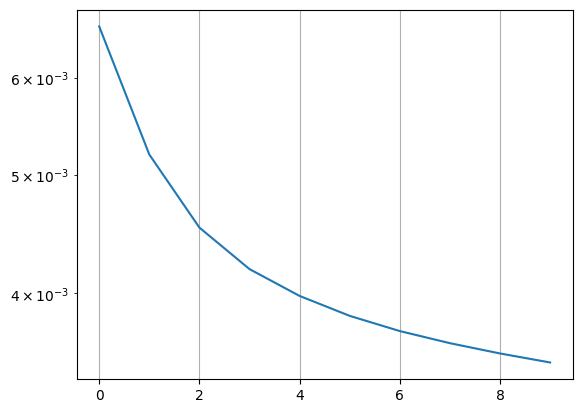

In [45]:
epochs = 10
ECparams, ECloss = ECtrain_network(ECparams, de_points, zsensors, epochs)

plt.semilogy(ECloss)
plt.grid()

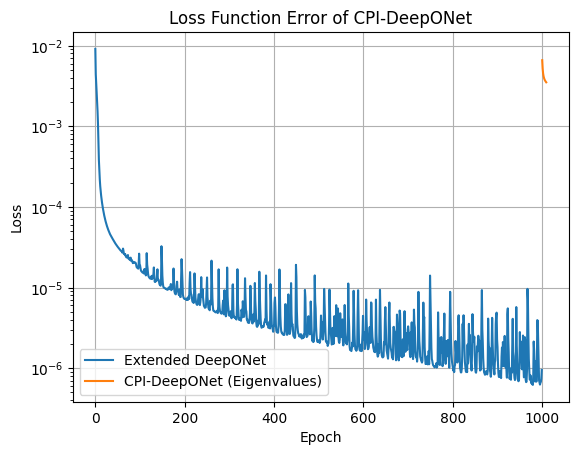

In [46]:
split = 1000
num_ep = np.arange(0, split, 1)
ECnum_ep = np.arange(split, split + epochs, 1)

plt.semilogy(num_ep, loss)
plt.semilogy(ECnum_ep, ECloss)
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.title("Loss Function Error of CPI-DeepONet")
plt.legend(['Extended DeepONet', 'CPI-DeepONet (Eigenvalues)'])
plt.grid()
#plt.savefig('Toda3_cpiE_loss_2500+2500ep.png')

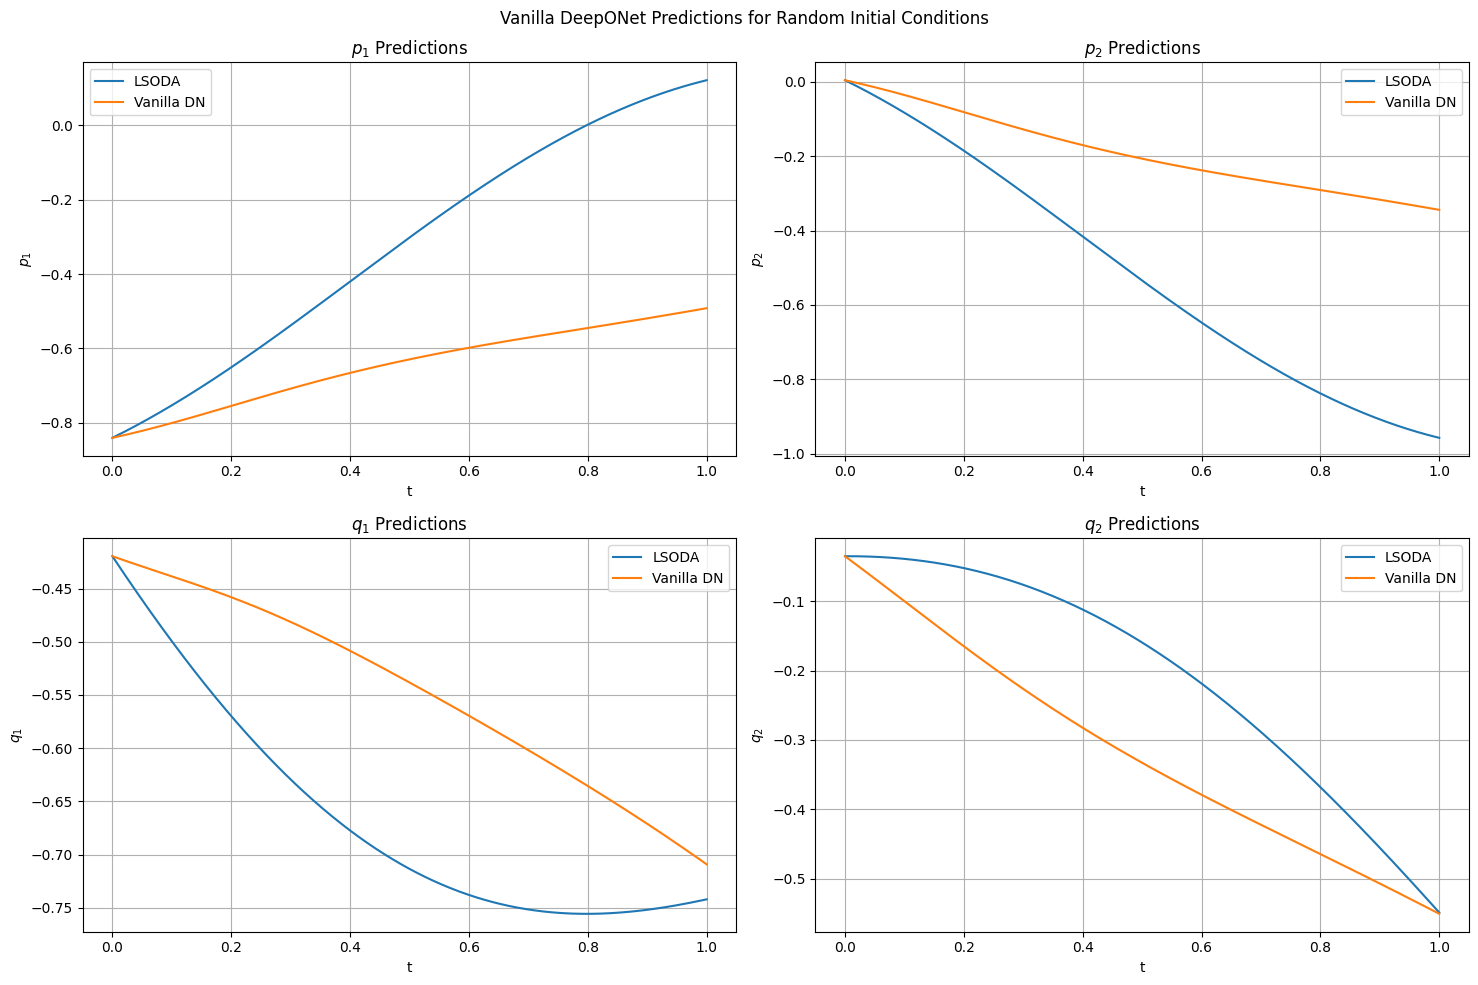

In [47]:
n = 500
t = np.linspace(t0, tfinal, n)

p1_init = np.random.uniform(-1.0, 1.0, size=(1,))
p2_init = np.random.uniform(-1.0, 1.0, size=(1,))
q1_init = np.random.uniform(-1.0, 1.0, size=(1,))
q2_init = np.random.uniform(-1.0, 1.0, size=(1,))
H_init = calc_H(p1_init, p2_init, q1_init, q2_init)
evals_init = calc_evals_pq(p1_init, p2_init, q1_init, q2_init)
e1_init, e2_init = evals_init[0], evals_init[1]


data_model = np.column_stack([p1_init, p2_init, q1_init, q2_init])
data_model = np.reshape(data_model, (-1,))
data_model = np.repeat(np.expand_dims(data_model, axis=0), n, axis=0)

H_model = np.repeat(np.expand_dims(H_init, axis=0), n, axis=0)

E_model = np.column_stack([e1_init, e2_init])
E_model = np.reshape(E_model, (-1,))
E_model = np.repeat(np.expand_dims(E_model, axis=0), n, axis=0)

H_model = np.repeat(np.expand_dims(H_init, axis=0), n, axis=0)
        
tHE_model = np.column_stack([t, H_model, E_model])

p1 = jax.vmap(ECvar_model, [0, 0, None, None])(tHE_model, data_model, 0, ECparams)
p2 = jax.vmap(ECvar_model, [0, 0, None, None])(tHE_model, data_model, 1, ECparams)
q1 = jax.vmap(ECvar_model, [0, 0, None, None])(tHE_model, data_model, 2, ECparams)
q2 = jax.vmap(ECvar_model, [0, 0, None, None])(tHE_model, data_model, 3, ECparams)


data_rk = np.column_stack([p1_init, p2_init, q1_init, q2_init])
data_rk = np.reshape(data_rk, (-1,))
t_rk = t
    
sol_rk = odeint(TodaLatt, data_rk, t_rk, rtol = 1e-13, atol = 1e-13)
p1_rk, p2_rk, q1_rk, q2_rk = sol_rk[:, 0], sol_rk[:, 1], sol_rk[:, 2], sol_rk[:, 3]
H_rk = calc_H(p1_rk, p2_rk, q1_rk, q2_rk)


fig = plt.figure(figsize=(15, 10))
fig.suptitle("Vanilla DeepONet Predictions for Random Initial Conditions")

plt.subplot(2, 2, 1)
plt.tight_layout()
plt.plot(t, p1_rk)
plt.plot(t, p1)
plt.grid()
plt.xlabel('t')
plt.ylabel(r'$p_1$')
plt.title(r'$p_1$' + ' Predictions')
plt.legend(['LSODA', 'Vanilla DN'])


plt.subplot(2, 2, 2)
plt.tight_layout()
plt.plot(t, p2_rk)
plt.plot(t, p2)
plt.grid()
plt.xlabel('t')
plt.ylabel(r'$p_2$')
plt.title(r'$p_2$' + ' Predictions')
plt.legend(['LSODA', 'Vanilla DN'])


plt.subplot(2, 2, 3)
plt.tight_layout()
plt.plot(t, q1_rk)
plt.plot(t, q1)
plt.grid()
plt.xlabel('t')
plt.ylabel(r'$q_1$')
plt.title(r'$q_1$' + ' Predictions')
plt.legend(['LSODA', 'Vanilla DN'])

plt.subplot(2, 2, 4)
plt.tight_layout()
plt.plot(t, q2_rk)
plt.plot(t, q2)
plt.grid()
plt.xlabel('t')
plt.ylabel(r'$q_2$')
plt.title(r'$q_2$' + ' Predictions')
plt.legend(['LSODA', 'Vanilla DN'])


#fig.savefig("Toda3_vanilla_preds_5000ep.png")

Exp 0
Exp 1
Exp 2
Exp 3
Exp 4


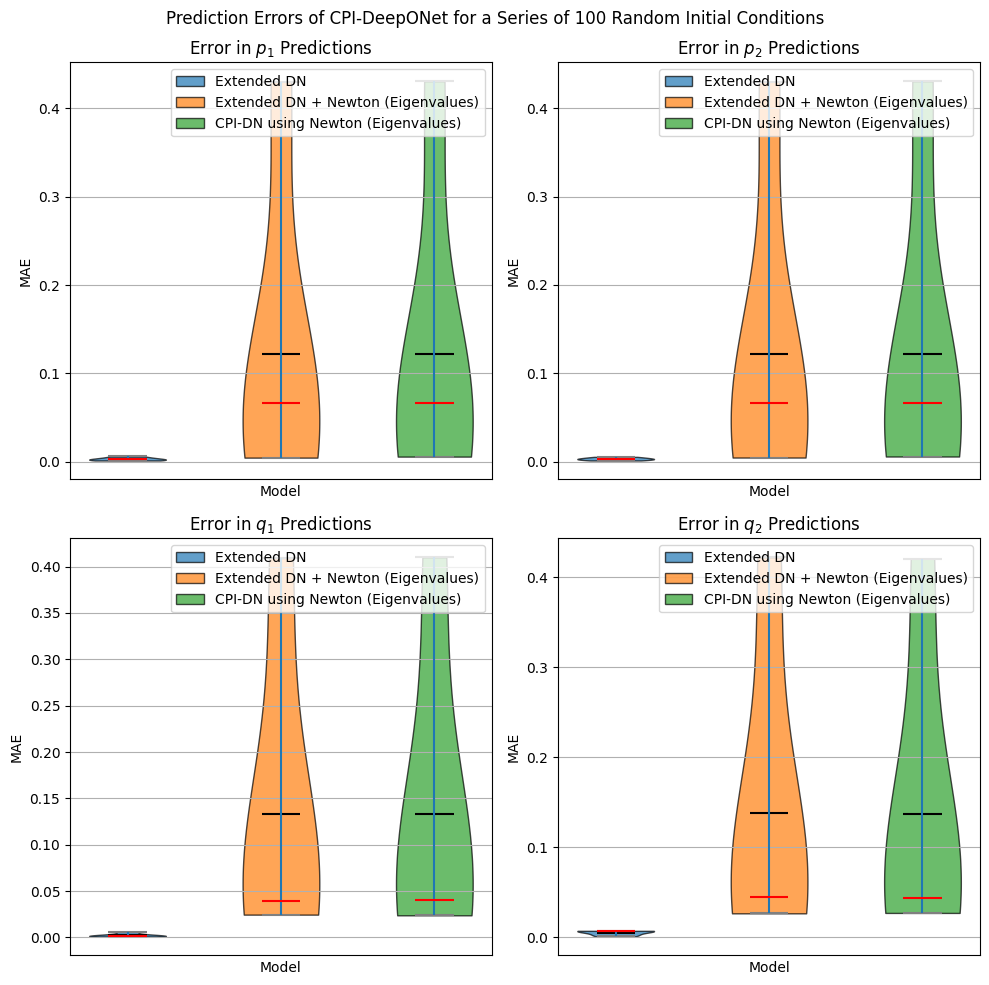

In [58]:
def run_test(num_vars, num_models, num_exp, models_lst, params_lst, labels_lst, bfgs_lst, newton_H_lst, newton_eig_lst) :

    n = 500
    t = np.linspace(t0, tfinal, n)
    
    
    preds = np.zeros((num_exp, num_models, num_vars, n))
    preds_error = np.zeros((num_exp, num_models, num_vars))

    for i in range(num_exp) :

        print("Exp", i)

        p1_init = np.random.uniform(-1.0, 1.0, size=(1,))
        p2_init = np.random.uniform(-1.0, 1.0, size=(1,))
        q1_init = np.random.uniform(-1.0, 1.0, size=(1,))
        q2_init = np.random.uniform(-1.0, 1.0, size=(1,))
        H_init = calc_H(p1_init, p2_init, q1_init, q2_init)
        evals_init = calc_evals_pq(p1_init, p2_init, q1_init, q2_init)
        e1_init, e2_init = evals_init[0], evals_init[1]
        
        
        data_model = np.column_stack([p1_init, p2_init, q1_init, q2_init])
        data_model = np.reshape(data_model, (-1,))
        data_model = np.repeat(np.expand_dims(data_model, axis=0), n, axis=0)
        
        H_model = np.repeat(np.expand_dims(H_init, axis=0), n, axis=0)
        
        E_model = np.column_stack([e1_init, e2_init])
        E_model = np.reshape(E_model, (-1,))
        E_model = np.repeat(np.expand_dims(E_model, axis=0), n, axis=0)
        
        H_model = np.repeat(np.expand_dims(H_init, axis=0), n, axis=0)
                
        tHE_model = np.column_stack([t, H_model, E_model])
                
        data_rk = np.column_stack([p1_init, p2_init, q1_init, q2_init])
        data_rk = np.reshape(data_rk, (-1,))
        t_rk = t
            
        sol_rk = odeint(TodaLatt, data_rk, t_rk, rtol = 1e-13, atol = 1e-13)
        p1_rk, p2_rk, q1_rk, q2_rk = sol_rk[:, 0], sol_rk[:, 1], sol_rk[:, 2], sol_rk[:, 3]
        H_rk = calc_H(p1_rk, p2_rk, q1_rk, q2_rk)
        

        for j in range(num_models) :

            model = models_lst[j]
            params = params_lst[j]

            for k in range(num_vars - 1) :


                val = jax.vmap(model, [0, 0, None, None])(tHE_model, data_model, k, params)
                preds[i, j, k] = val

                
            preds[i, j, 4] = calc_H(preds[i, j, 0], preds[i, j, 1], preds[i, j, 2], preds[i, j, 3])

            # if j in bfgs_lst :
                
            #     args_arr = np.column_stack([preds[i, j, 0], preds[i, j, 1], preds[i, j, 2], preds[i, j, 3]])
                
            #     H_arr = tH_model[:, 1:]
        
            #     xbfgs = find_min_bfgs(args_arr, H_arr)                

            #     for l in range(4) :

            #         preds[i, j, l] = xbfgs[:, l]

                
            #     preds[i, j, 4] = Hcalc_H(preds[i, j, 0], preds[i, j, 1], preds[i, j, 2], preds[i, j, 3])  


            if j in newton_H_lst :
                
                args_arr = np.column_stack([preds[i, j, 0], preds[i, j, 1], preds[i, j, 2], preds[i, j, 3]])
                
                H_arr = tHE_model[:, 1:2]
            
                xnewtonH = find_min_newton_H(args_arr, H_arr)                
            
                for l in range(num_vars - 1) :
            
                    preds[i, j, l] = xnewtonH[:, l]
            
                
                preds[i, j, 4] = calc_H(preds[i, j, 0], preds[i, j, 1], preds[i, j, 2], preds[i, j, 3])
            
            
            if j in newton_eig_lst :

                # print(j)
                
                args_arr = np.column_stack([preds[i, j, 0], preds[i, j, 1], preds[i, j, 2], preds[i, j, 3]])
                
                E_arr = tHE_model[:, 2:]
            
                xnewtoneig = find_min_newton_eig(args_arr, E_arr)                
            
                for l in range(num_vars - 1) :
            
                    preds[i, j, l] = xnewtoneig[:, l]
            
                
                preds[i, j, 4] = calc_H(preds[i, j, 0], preds[i, j, 1], preds[i, j, 2], preds[i, j, 3])
              

            for m in range(num_vars - 1) :

                preds_error[i, j, m] = np.mean(np.abs(sol_rk[:, m] - preds[i, j, m]))

            preds_error[i, j, 4] = np.mean(np.abs(H_rk - preds[i, j, 4]))
            


    x_labels = [r'$p_1$', r'$p_2$', r'$q_1$', r'$q_2$', 'H'] 
        
    # Set up the figure
    fig = plt.figure(figsize=(10, 10))
    fig.suptitle('Prediction Errors of CPI-DeepONet for a Series of 100 Random Initial Conditions')
    
    # Define colors for each model (adjust color palette as needed)
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']   # Example colors for each model
    
    for j in range(num_vars - 1):
        plt.subplot(2, 2, j + 1)


        q1 = np.percentile(preds_error[:, 0, j], 25)
        q3 = np.percentile(preds_error[:, 0, j], 75)
        iqr = q3 - q1

        #plt.ylim(0.0, q3 + 1.5 * iqr)
        
        # Prepare data for each model for the current variable (j)
        data = [preds_error[:, alpha, j] for alpha in range(num_models)]
        
        # Create the violin plot with custom colors
        vp = plt.violinplot(data, positions=range(num_models), showmeans=True, showmedians=True)
        
        # Customize the colors of the violins
        for i in range(num_models):
            vp['bodies'][i].set_facecolor(colors[i])  # Set face color for each model
            vp['bodies'][i].set_edgecolor('black')   # Set edge color for each model
            vp['bodies'][i].set_alpha(0.7)            # Set transparency
        
        # Customize mean and median lines
        vp['cmeans'].set_color('black')  # Mean line color
        vp['cmedians'].set_color('red')
        vp['cmins'].set_color('gray')
        vp['cmaxes'].set_color('gray')# Median line color
    
        # Add labels, title, and grid
        plt.ylabel("MAE")
        if j == 4:
            plt.title("Error in " + x_labels[j] + " from Predictions")
        else:
            plt.title("Error in " + x_labels[j] + " Predictions")
        plt.grid(True, axis='y')
    
        # Add legend (outside the plot)
        plt.xticks([])  # Remove vertical axis ticks
        plt.xlabel("Model")  # Remove vertical axis label
        plt.legend(labels=labels_lst, loc='upper right')
    
    # Adjust the layout and display the plot
    plt.tight_layout()
    plt.show()
    

    
    #fig.savefig('Toda3_cpi_violinmae_2500+2500ep.png')
    return preds, preds_error, (p1_rk, p2_rk, q1_rk, q2_rk, H_rk)


preds, preds_error, (p1_rk, p2_rk, q1_rk, q2_rk, H_rk) = run_test(num_vars = 5, num_models = 3, num_exp = 5, \
         models_lst = [var_model, var_model, ECvar_model], \
         params_lst = [params, params, ECparams], \
         labels_lst = ['Extended DN', 'Extended DN + Newton (Eigenvalues)', 'CPI-DN using Newton (Eigenvalues)'], \
         bfgs_lst = [], 
         newton_H_lst = [],
         newton_eig_lst = [1])